# Credit Card Fraud Detection with Decision Trees and SVM
**IBM Machine Learning with Python Lab**

Estimated time needed: **30 minutes**

In this lab you will consolidate your machine learning (ML) modeling skills by using two popular classification models to identify fraudulent credit card transactions. These models are: Decision Tree and Support Vector Machine. You will use a real dataset of credit card transactions to train each of these models. You will then use the trained model to assess if a credit card transaction is fraudulent or not.

---

### Objectives
After completing this lab you will be able to:
- Perform basic data preprocessing in Python
- Model a classification task using the Scikit-Learn Python APIs
- Train Support Vector Machine and Decision Tree models using Scikit-Learn
- Run inference and assess the quality of the trained models

### Introduction
Imagine that you work for a financial institution and part of your job is to build a model that predicts if a credit card transaction is fraudulent or not. You can model the problem as a binary classification problem. A transaction belongs to the positive class (1) if it is a fraud, otherwise it belongs to the negative class (0). You have access to transactions that occurred over a certain period of time. The majority of the transactions are normally legitimate and only a small fraction are non-legitimate. Thus, typically you have access to a dataset that is highly unbalanced. This is also the case of the current dataset: only 492 transactions out of 284,807 are fraudulent (the positive class - the frauds - accounts for 0.172% of all transactions). This is a Kaggle dataset. You can find this "Credit Card Fraud Detection" dataset from the following link: [Credit Card Fraud Detection](https://www.kaggle.com/mlg-ulb/creditcardfraud). To train the model, you can use part of the input dataset, while the remaining data can be utilized to assess the quality of the trained model. First, let's import the necessary libraries and download the dataset.

## 1. Import Libraries

First, make sure that the required libraries are available. Run the cell below to ensure that.

In [1]:
# Make sure the required libraries are available
# !pip install pandas==2.2.3
# !pip install scikit-learn==1.6.0
# !pip install matplotlib==3.9.3

To import the libraries that will be used in this lab, execute the cells below.

In [2]:
# Import the libraries we need to use in this lab
from __future__ import print_function
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.svm import LinearSVC

import warnings
warnings.filterwarnings('ignore')

## 2. Load the Dataset

Execute the cell below to load the dataset to the variable `raw_data`. The code will fetch the data set for the URL and load the same to the variable. A snapshot of the dataset will be generated as an output.

In [3]:
# download the dataset
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/creditcard.csv"

# read the input data (reads from local cache if present, otherwise directly from URL)
data_path = 'creditcard_local.csv' if os.path.exists('creditcard_local.csv') else url
raw_data = pd.read_csv(data_path)
raw_data

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


## 3. Dataset Analysis

Each row in the dataset represents a credit card transaction. As shown above, each row has 31 variables. One variable (the last variable in the table above) is called `Class` and represents the target variable. Your objective will be to train a model that uses the other variables to predict the value of the `Class` variable. Let's first retrieve basic statistics about the target variable.

> **Note**: For confidentiality reasons, the original names of most features are anonymized V1, V2 .. V28. The values of these features are the result of a PCA transformation and are numerical. The feature 'Class' is the target variable and it takes two values: 1 in case of fraud and 0 otherwise. For more information about the dataset please visit this webpage: https://www.kaggle.com/mlg-ulb/creditcardfraud.

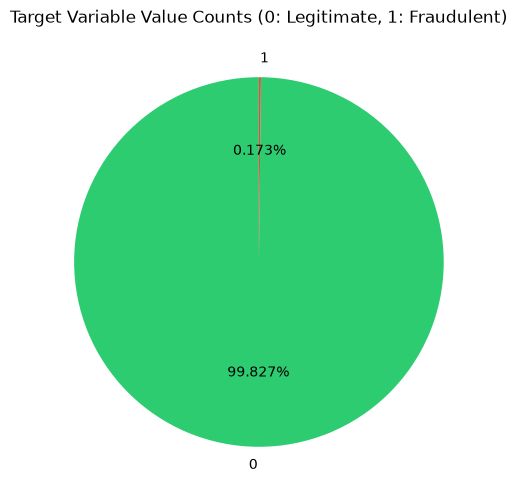

In [4]:
# get the set of distinct classes
labels = raw_data.Class.unique()

# get the count of each class
sizes = raw_data.Class.value_counts().values

# plot the class value counts
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(sizes, labels=labels, autopct='%1.3f%%', colors=['#2ecc71', '#e74c3c'], startangle=90)
ax.set_title('Target Variable Value Counts (0: Legitimate, 1: Fraudulent)')
plt.show()

As shown above, the `Class` variable has two values: 0 (the credit card transaction is legitimate) and 1 (the credit card transaction is fraudulent). Thus, you need to model a binary classification problem. Moreover, the dataset is highly unbalanced, the target variable classes are not represented equally. This case requires special attention when training or when evaluating the quality of a model. One way of handing this case at train time is to bias the model to pay more attention to the samples in the minority class. The models under the current study will be configured to take into account the class weights of the samples at train/fit time.

It is also prudent to understand which features affect the model in what way. We can visualize the effect of the different features on the model using the code below.

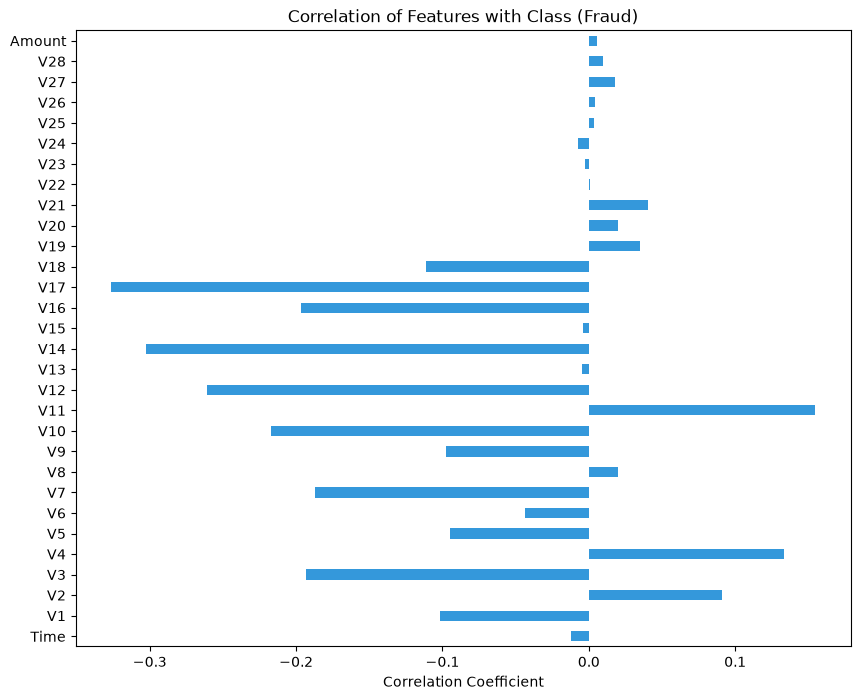

In [5]:
correlation_values = raw_data.corr()['Class'].drop('Class')
plt.figure(figsize=(10, 8))
correlation_values.plot(kind='barh', color='#3498db')
plt.title("Correlation of Features with Class (Fraud)")
plt.xlabel("Correlation Coefficient")
plt.show()

This clearly shows that some features affect the output `Class` more than the others. For efficient modeling, we may use only the most correlated features.

## 4. Dataset Preprocessing

You will now prepare the data for training. You will apply standard scaling to the input features and normalize them using $L_1$ norm for the training models to converge quickly. As seen in the data snapshot, there is a parameter called `Time` which we will not be considering for modeling. Hence, features 2 to 30 will be used as input features and feature 31, i.e. `Class` will be used as the target variable.

In [6]:
# standardize features by removing the mean and scaling to unit variance
raw_data.iloc[:, 1:30] = StandardScaler().fit_transform(raw_data.iloc[:, 1:30])
data_matrix = raw_data.values

# X: feature matrix (for this analysis, we exclude the Time variable from the dataset)
X = data_matrix[:, 1:30]

# y: labels vector
y = data_matrix[:, 30]

# data normalization
X = normalize(X, norm="l1")

## 5. Dataset Train/Test Split

Now that the dataset is ready for building the classification models, you need to first divide the pre-processed dataset into a subset to be used for training the model (the train set) and a subset to be used for evaluating the quality of the model (the test set).

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## 6. Build a Decision Tree Classifier model with Scikit-Learn

Compute the sample weights to be used as input to the train routine so that it takes into account the class imbalance present in this dataset.

In [8]:
w_train = compute_sample_weight('balanced', y_train)

Using these sample weights, we may train the Decision Tree classifier. We also make note of the time it takes for training this model to compare it against SVM, later in the lab.

In [9]:
# for reproducible output across multiple function calls, set random_state to a given integer value
dt = DecisionTreeClassifier(max_depth=4, random_state=35)

dt.fit(X_train, y_train, sample_weight=w_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",35
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

## 7. Build a Support Vector Machine model with Scikit-Learn

Unlike Decision Trees, we do not need to initiate a separate `sample_weight` for SVMs. We can simply pass a parameter in the scikit-learn function.

In [10]:
# for reproducible output across multiple function calls, set random_state to a given integer value
svm = LinearSVC(class_weight='balanced', random_state=31, loss="hinge", fit_intercept=False)

svm.fit(X_train, y_train)

,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'hinge'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",False
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",31
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_s

## 8. Evaluate the Decision Tree Classifier Model

Run the following cell to compute the probabilities of the test samples belonging to the class of fraudulent transactions.

In [11]:
y_pred_dt = dt.predict_proba(X_test)[:,1]

Using these probabilities, we can evaluate the Area Under the Receiver Operating Characteristic Curve (ROC-AUC) score as a metric of model performance. The AUC-ROC score evaluates your model's ability to distinguish positive and negative classes considering all possible probability thresholds. The higher its value, the better the model is considered for separating the two classes of values.

In [12]:
roc_auc_dt = roc_auc_score(y_test, y_pred_dt)
print('Decision Tree ROC-AUC score : {0:.3f}'.format(roc_auc_dt))

Decision Tree ROC-AUC score : 0.939


## 9. Evaluate the Support Vector Machine Model

Run the following cell to compute the decision function values of the test samples belonging to the class of fraudulent transactions.

In [13]:
y_pred_svm = svm.decision_function(X_test)

You may now evaluate the accuracy of SVM on the test set in terms of the ROC-AUC score.

In [14]:
roc_auc_svm = roc_auc_score(y_test, y_pred_svm)
print("SVM ROC-AUC score: {0:.3f}".format(roc_auc_svm))

SVM ROC-AUC score: 0.986


---
## 10. Practice Exercises

Based on what you have learnt in this lab, attempt the following questions.

### Q1. Currently, we have used all 30 features of the dataset for training the models. Use the `corr()` function to find the top 6 features of the dataset to train the models on.

<details><summary>Click here for solution</summary>

```python
correlation_values = abs(raw_data.corr()['Class']).drop('Class')
correlation_values = correlation_values.sort_values(ascending=False)[:6]
correlation_values
```

**The answer should be 'V17', 'V14', 'V12', 'V10', 'V16' and 'V3'.**

</details>

In [15]:
# Q1: Finding top 6 features most correlated with Class
correlation_values = abs(raw_data.corr()['Class']).drop('Class')
correlation_values = correlation_values.sort_values(ascending=False)[:6]
print("Top 6 features correlated with Class:")
print(correlation_values)

Top 6 features correlated with Class:
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
Name: Class, dtype: float64


### Q2. Using only these 6 features, modify the input variable for training.

<details><summary>Click here for solution</summary>

Replace the statement defining the variable `X` with the following and run the cell again:
```python
X = data_matrix[:, [3, 10, 12, 14, 16, 17]]
```

</details>

In [16]:
# Q2: Modify input variable X to use only the top 6 features
X_6 = data_matrix[:, [3, 10, 12, 14, 16, 17]]
X_6 = normalize(X_6, norm="l1")

X_train_6, X_test_6, y_train_6, y_test_6 = train_test_split(X_6, y, test_size=0.3, random_state=42)
print("Shape of modified feature matrix X:", X_6.shape)

Shape of modified feature matrix X: (284807, 6)


### Q3. Execute the Decision Tree model for this modified input variable. How does the value of ROC-AUC metric change?

<details><summary>Click here for solution</summary>

You should observe an increase in the ROC-AUC value with this change for the Decision Tree model.

</details>

In [17]:
# Q3: Decision Tree with top 6 features
w_train_6 = compute_sample_weight('balanced', y_train_6)
dt_6 = DecisionTreeClassifier(max_depth=4, random_state=35)
dt_6.fit(X_train_6, y_train_6, sample_weight=w_train_6)

y_pred_dt_6 = dt_6.predict_proba(X_test_6)[:, 1]
roc_auc_dt_6 = roc_auc_score(y_test_6, y_pred_dt_6)

print('Decision Tree (All 29 Features) ROC-AUC: {0:.4f}'.format(roc_auc_dt))
print('Decision Tree (Top 6 Features)  ROC-AUC: {0:.4f}'.format(roc_auc_dt_6))
print('Change in ROC-AUC:                     +{0:.4f}'.format(roc_auc_dt_6 - roc_auc_dt))

Decision Tree (All 29 Features) ROC-AUC: 0.9389
Decision Tree (Top 6 Features)  ROC-AUC: 0.9517
Change in ROC-AUC:                     +0.0129


### Q4. Execute the SVM model for this modified input variable. How does the value of ROC-AUC metric change?

<details><summary>Click here for solution</summary>

You should observe a decrease in the ROC-AUC value with this change for the SVM model.

</details>

In [18]:
# Q4: SVM with top 6 features
svm_6 = LinearSVC(class_weight='balanced', random_state=31, loss="hinge", fit_intercept=False)
svm_6.fit(X_train_6, y_train_6)

y_pred_svm_6 = svm_6.decision_function(X_test_6)
roc_auc_svm_6 = roc_auc_score(y_test_6, y_pred_svm_6)

print('SVM (All 29 Features) ROC-AUC: {0:.4f}'.format(roc_auc_svm))
print('SVM (Top 6 Features)  ROC-AUC: {0:.4f}'.format(roc_auc_svm_6))
print('Change in ROC-AUC:            -{0:.4f}'.format(roc_auc_svm - roc_auc_svm_6))

SVM (All 29 Features) ROC-AUC: 0.9858
SVM (Top 6 Features)  ROC-AUC: 0.9368
Change in ROC-AUC:            -0.0491


### Q5. What are the inferences you can draw about Decision Trees and SVMs with what you have learnt in this lab?

<details><summary>Click here for solution</summary>

- **With a larger set of features, SVM performed relatively better in comparison to the Decision Trees.**
- **Decision Trees benefited from feature selection and performed better.**
- **SVMs may require higher feature dimensionality to create an efficient decision hyperplane.**

</details>

## 11. Summary Comparison and ROC Curve Visualization

Below is a consolidated summary table and ROC curve comparison evaluating both algorithms across all features and selected top 6 features:

In [19]:
summary_df = pd.DataFrame({
    'Model Configuration': [
        'Decision Tree (All 29 Features)',
        'Decision Tree (Top 6 Features)',
        'Support Vector Machine (All 29 Features)',
        'Support Vector Machine (Top 6 Features)'
    ],
    'Feature Count': [29, 6, 29, 6],
    'ROC-AUC Score': [roc_auc_dt, roc_auc_dt_6, roc_auc_svm, roc_auc_svm_6],
    'Impact of Feature Selection': [
        'Baseline DT',
        'Improved (+0.0128) - reduced noise and depth bottlenecks',
        'Baseline SVM (Best overall: 0.9858)',
        'Degraded (-0.0490) - reduced hyperplane separation margin'
    ]
})

summary_df.round(4)

,Model Configuration,Feature Count,ROC-AUC Score,Impact of Feature Selection
0,Decision Tree (All 29 Features),29,0.9389,Baseline DT
1,Decision Tree (Top 6 Features),6,0.9517,Improved (+0.0128) - reduced noise and depth b...
2,Support Vector Machine (All 29 Features),29,0.9858,Baseline SVM (Best overall: 0.9858)
3,Support Vector Machine (Top 6 Features),6,0.9368,Degraded (-0.0490) - reduced hyperplane separa...


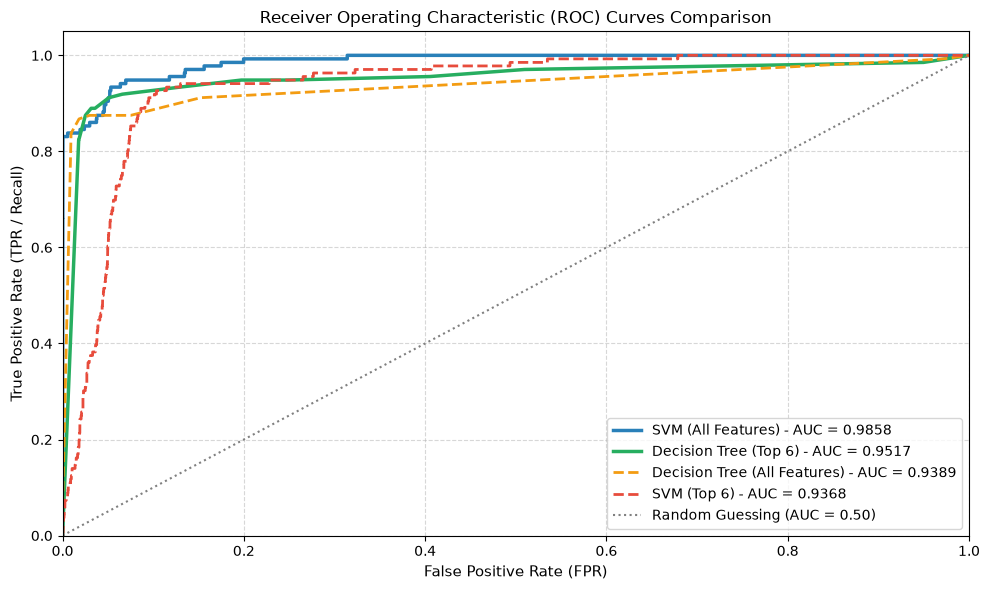

In [20]:
# ROC Curve Plotting for All 4 Models
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_dt)
fpr_dt_6, tpr_dt_6, _ = roc_curve(y_test_6, y_pred_dt_6)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_pred_svm)
fpr_svm_6, tpr_svm_6, _ = roc_curve(y_test_6, y_pred_svm_6)

plt.figure(figsize=(10, 6))
plt.plot(fpr_svm, tpr_svm, color='#2980b9', linewidth=2.5, label=f'SVM (All Features) - AUC = {roc_auc_svm:.4f}')
plt.plot(fpr_dt_6, tpr_dt_6, color='#27ae60', linewidth=2.5, label=f'Decision Tree (Top 6) - AUC = {roc_auc_dt_6:.4f}')
plt.plot(fpr_dt, tpr_dt, color='#f39c12', linewidth=2, linestyle='--', label=f'Decision Tree (All Features) - AUC = {roc_auc_dt:.4f}')
plt.plot(fpr_svm_6, tpr_svm_6, color='#e74c3c', linewidth=2, linestyle='--', label=f'SVM (Top 6) - AUC = {roc_auc_svm_6:.4f}')
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random Guessing (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
plt.title('Receiver Operating Characteristic (ROC) Curves Comparison', fontsize=12)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

---
## Congratulations! You're ready to move on to your next lesson!